In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

In [30]:
iris = load_iris()

In [31]:
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
y = iris.target

In [32]:
print(X.head())
print(X.shape)
print(X.isnull().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
(150, 4)
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


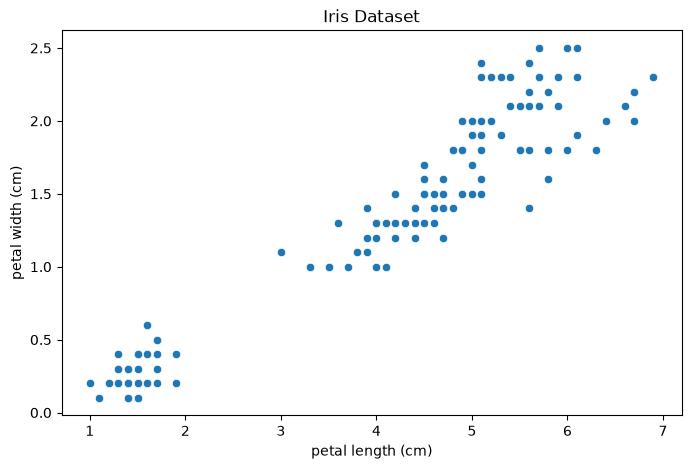

In [33]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=X,
    x="petal length (cm)",
    y="petal width (cm)"
)
plt.title("Iris Dataset")
plt.show()

In [34]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [35]:
model = DBSCAN(
    eps = 0.7,
    min_samples=5
)

In [36]:
labels = model.fit_predict(X_scaled)

In [37]:
print(labels)
clusters = len(set(labels))-(1 if -1 in labels else 0)
noise = sum(labels==-1)
print(clusters)
print(noise)

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1 -1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]
2
6


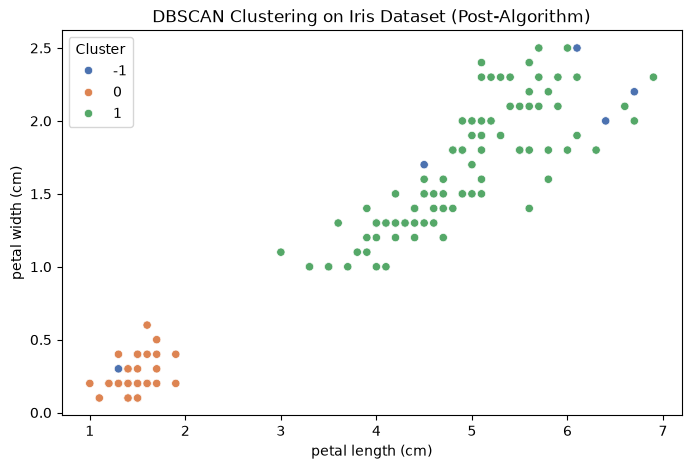

In [38]:
X_plot = X[["petal length (cm)", "petal width (cm)"]].copy()
X_plot["Cluster"] = labels
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X_plot,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Cluster",
    palette="deep"
)
plt.title("DBSCAN Clustering on Iris Dataset (Post-Algorithm)")
plt.show()